# 1. Before Tuning

# lab2 — real_jack (.mov) → sign → text
อ่าน `data_test/real_jack/**/*.mov` → แปลงเป็น mp4 → `SignPipeline` → ข้อความ

In [1]:
print("hello world")

hello world


In [2]:
# 1) setup + แปลง .mov -> .mp4 (25 fps, H.264, หมุนตาม metadata ของ iPhone อัตโนมัติ)
#    รันซ้ำได้เสมอ: ไฟล์ใหม่ที่เพิ่มเข้ามาใน SRC จะถูกหาเจอและแปลงเพิ่ม, ไฟล์เดิมข้าม
import sys, subprocess, shutil, time
from pathlib import Path
import pandas as pd
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))

SRC  = ROOT / "data_test" / "iphone_test"        # Sentence-*/Sentence/*.MOV , Word-*/Word/*.MOV (หา recursive)
CONV = ROOT / "cache" / "iphone_test_mp4"
CONV.mkdir(parents=True, exist_ok=True)
VOCAB = "conversation"                           # หรือ "full"

def kind_of(p):                                  # ชนิดจากชื่อโฟลเดอร์: Word / Sentence
    top = p.relative_to(SRC).parts[0].lower()
    return "word" if top.startswith("word") else "sentence" if top.startswith("sentence") else "?"

movs = sorted(p for p in SRC.rglob("*") if p.suffix.lower() == ".mov")
vids = {}                                        # key = "<kind>/<ชื่อไฟล์>"
for p in movs:
    key = f"{kind_of(p)}/{p.name}"
    out = CONV / f"{kind_of(p)}_{p.stem}.mp4"
    if not out.exists():
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(p), "-vf", "fps=25", "-an",
                        "-c:v", "libx264", "-pix_fmt", "yuv420p", str(out)], check=True)
    vids[key] = out
print(len(vids), "ไฟล์ .mov ->", CONV)

14 ไฟล์ .mov -> d:\SLM-labs\SLM-Labs-SignDINO\cache\iphone_test_mp4


In [3]:
# 2) โหลดโมเดลครั้งเดียว แล้ว predict เฉพาะไฟล์ที่ยังไม่เคยทำ (รันซ้ำหลังเพิ่มไฟล์ = ทำแค่ไฟล์ใหม่)
if "pipe" not in globals():
    from modules.pipeline import SignPipeline
    pipe = SignPipeline(backend="onnx", device="cpu", vocab=VOCAB, use_llm=False)
results = globals().get("results", {})

for name, mp4 in vids.items():
    if name in results: continue
    t = time.perf_counter()
    try:
        results[name] = pipe.run(mp4)
    except Exception as e:
        results[name] = dict(error=repr(e), segments=[], sentence="")
    print(f"{name}: {time.perf_counter()-t:.1f}s")

sentence/IMG_3302.MOV: 18.6s
sentence/IMG_3303.MOV: 10.1s
sentence/IMG_3304.MOV: 16.8s
sentence/IMG_3305.MOV: 11.3s
sentence/IMG_3307.MOV: 15.5s
word/IMG_3293.MOV: 4.4s
word/IMG_3295.MOV: 4.6s
word/IMG_3296.MOV: 3.6s
word/IMG_3297.MOV: 6.3s
word/IMG_3298.MOV: 3.1s
word/IMG_3299.MOV: 3.7s
word/IMG_3308.MOV: 3.6s
word/IMG_3309.MOV: 3.9s
word/IMG_3311.MOV: 6.6s


In [4]:
# 3) ต่อ segment (ท่าที่ตรวจเจอ): top-3 คำ + score  (ไม่มี threshold — แสดงทุก segment รวม transition)
#    score = similarity ของ embedding กับ bank ; p_correct = ความน่าจะเป็นที่ top-1 ถูก (calibrated)
rows = []
for name, r in sorted(results.items()):
    if r.get("error"):
        rows.append(dict(file=name, seg="-", time="-", top3=r["error"])); continue
    for i, s in enumerate(r["segments"]):
        c = s.get("candidates") or []
        rows.append(dict(file=name, seg=i, time=f"{s['t0']}-{s['t1']}s", status=s.get("status"),
                         top3="  |  ".join(f"{x['word']} ({x['score']:.3f})" for x in c[:3]) or s.get("nearest"),
                         p_correct=round(s.get("p_correct", float("nan")), 3)))
df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 100); pd.set_option("display.max_rows", 500)
display(df)
df.to_csv(CONV / "predictions_top3.csv", index=False, encoding="utf-8-sig")

,file,seg,time,status,top3,p_correct
0,sentence/IMG_3302.MOV,0,0.32-1.44s,accepted,สวัสดี (0.822) | พรุ่งนี้ (0.503) | เที่ยว (0.539),0.859
1,sentence/IMG_3302.MOV,1,1.44-2.72s,accepted,ฉัน (0.862) | เกิด (0.633) | ชอบ (0.605),0.857
2,sentence/IMG_3302.MOV,2,2.72-4.48s,uncertain,ชื่อ (0.612) | ภาษามือ (0.419) | ไข่ (0.359),0.548
3,sentence/IMG_3302.MOV,3,4.48-5.44s,uncertain,ถูก (0.557) | ยาย (0.549) | ผิด (0.501),0.271
4,sentence/IMG_3302.MOV,4,5.44-7.04s,unknown,ฉัน (0.824) | เกิด (0.758) | ภูมิใจ (0.580),0.672
5,sentence/IMG_3302.MOV,5,7.04-8.16s,accepted,ชอบ (0.834) | ฉัน (0.695) | แฟน (0.495),0.903
6,sentence/IMG_3302.MOV,6,8.32-8.96s,uncertain,กิน (0.594) | เกิด (0.601) | ข้าว (0.592),0.331
7,sentence/IMG_3302.MOV,7,8.96-10.4s,uncertain,แมว (0.707) | เก้า (0.354) | เที่ยว (0.371),0.767
8,sentence/IMG_3303.MOV,0,0.0-1.12s,uncertain,ฉัน (0.805) | เกิด (0.554) | เหงา (0.500),0.738
9,sentence/IMG_3303.MOV,1,1.12-3.04s,unknown,สบายดี (0.712) | มีความสุข (0.455) | ยินดีด้วย (0.372),0.295


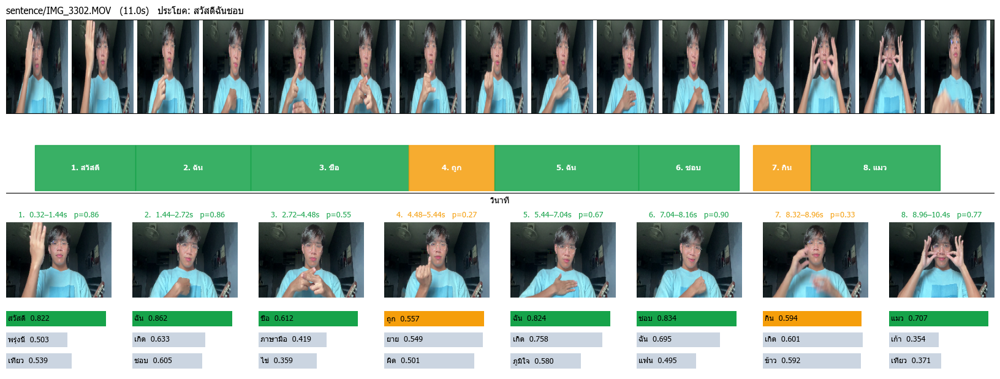

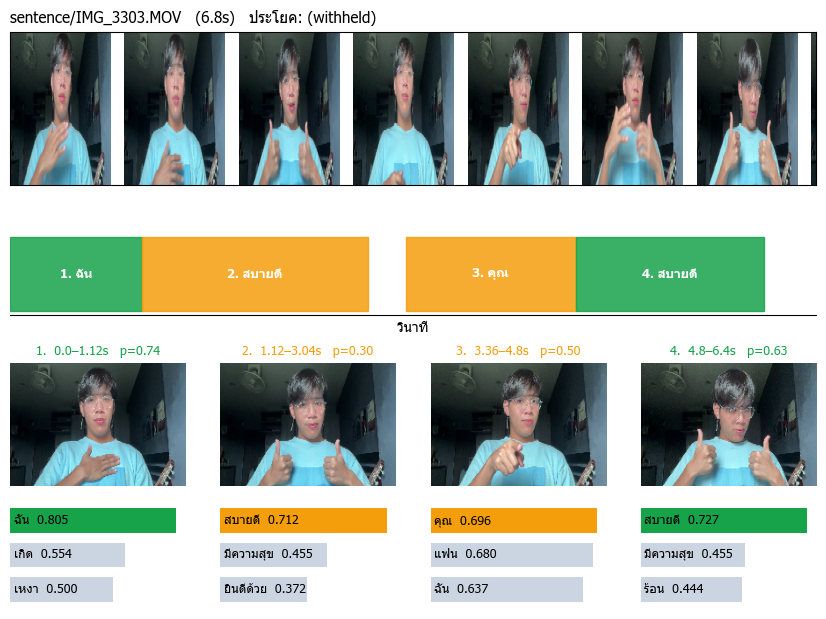

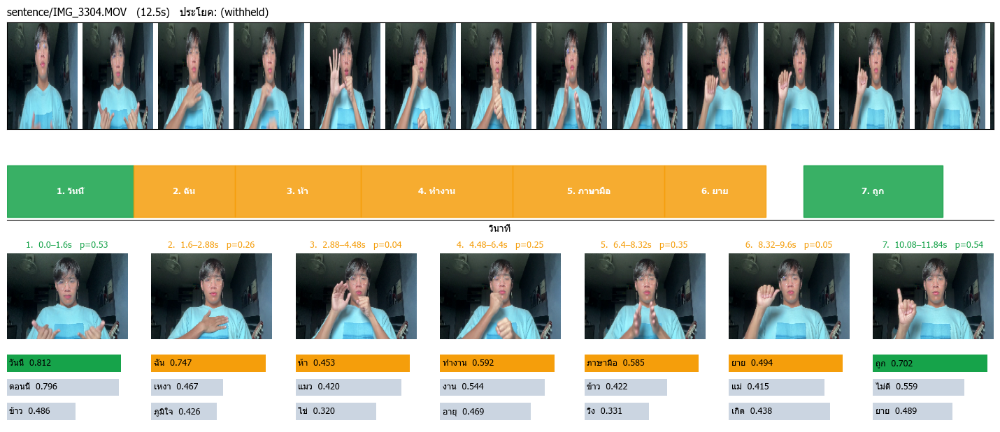

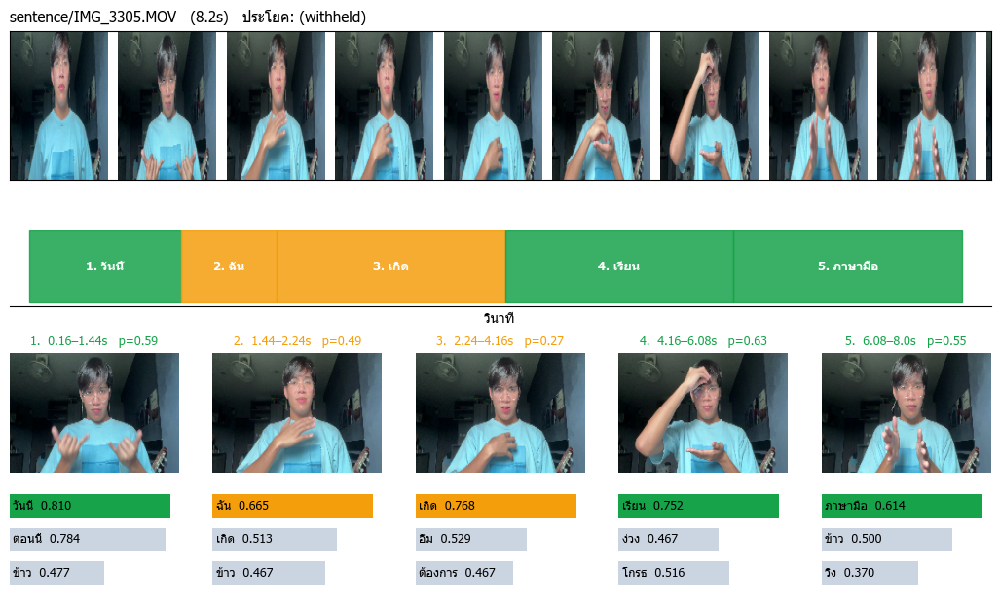

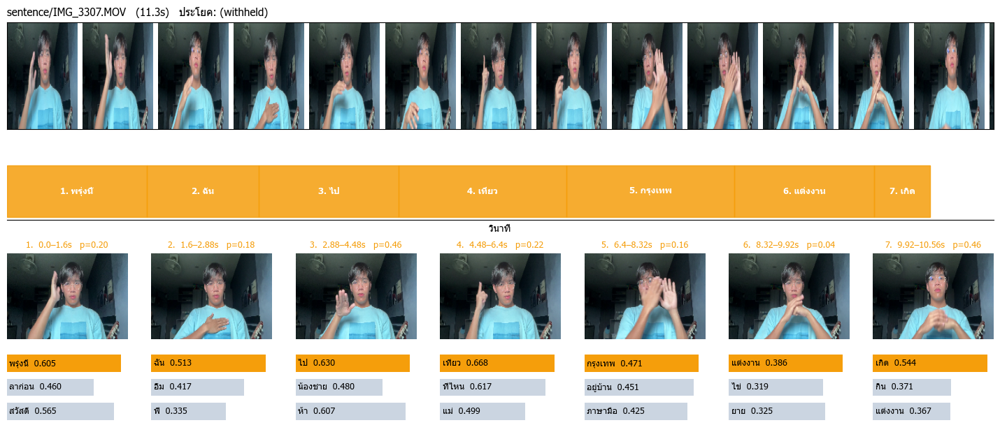

...

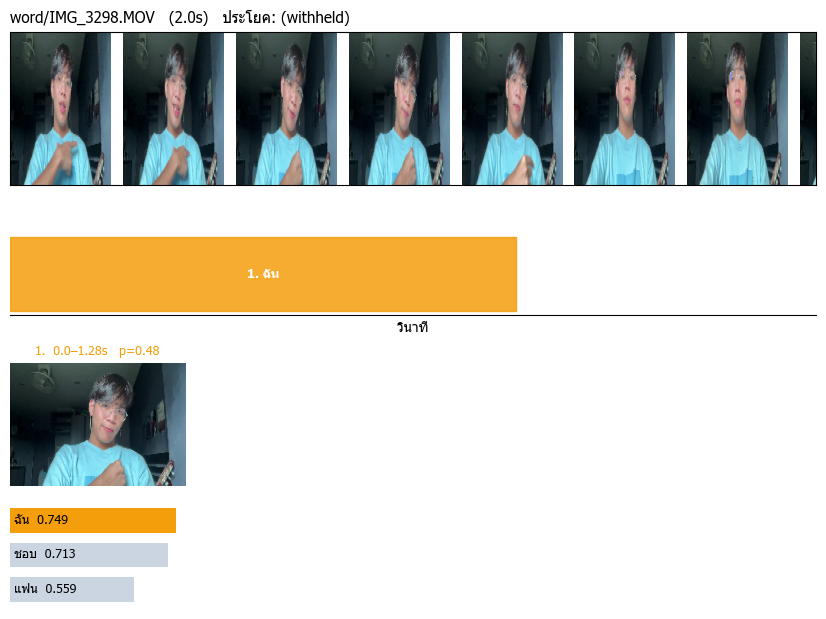

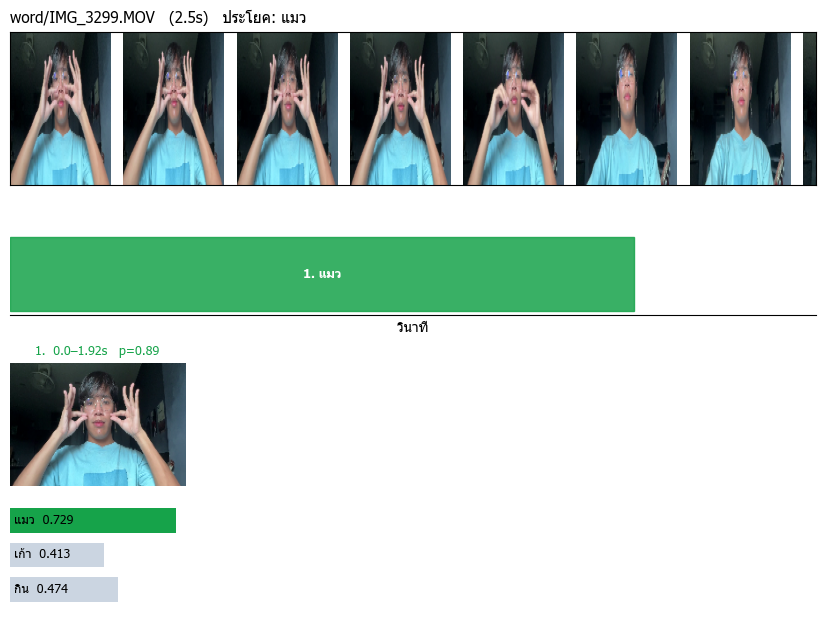

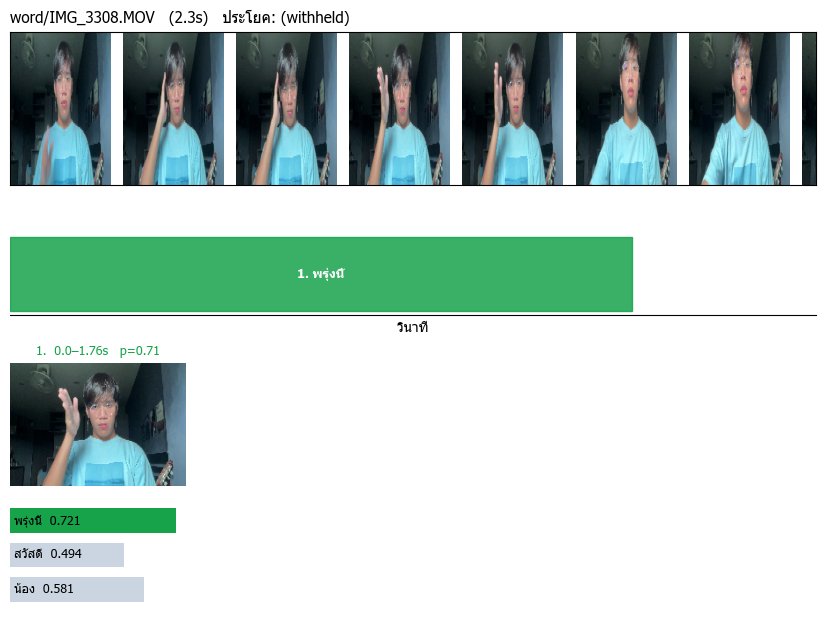

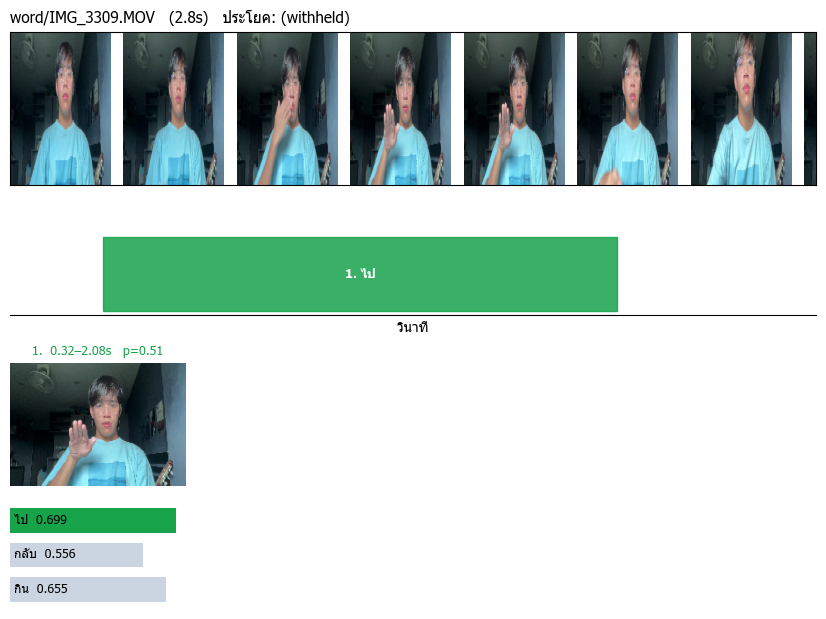

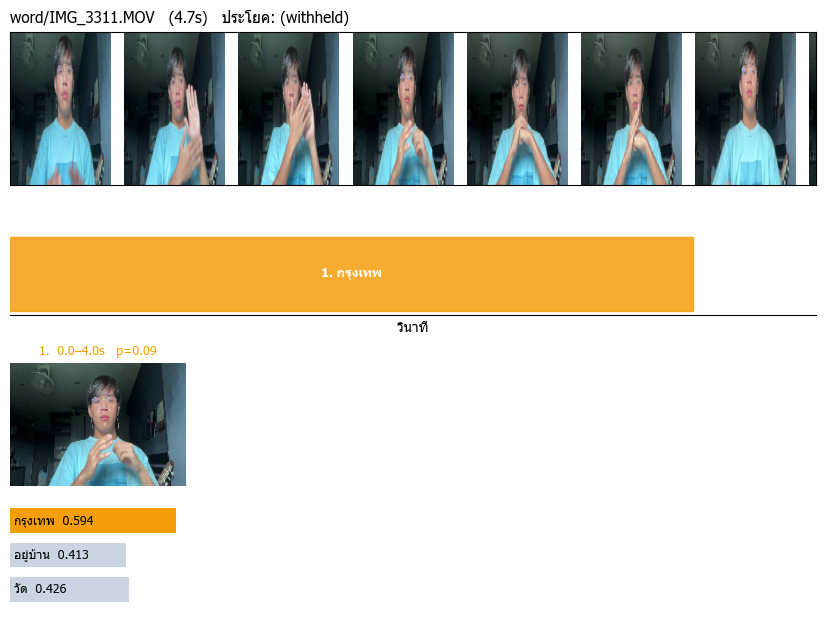

In [5]:
# 4) visualize ต่อคลิป: แถบเฟรมจากวิดีโอ (แกนเวลาเดียวกัน) + ช่วงท่าที่ระบบตรวจเจอ + ranking top-3 ของแต่ละท่า
#    เขียว = มั่นใจ, ส้ม = ไม่แน่ใจ (p_correct < UNCERTAIN), เทา = transition (ไม่ใช่ท่าคำ)
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams["font.family"] = ["Tahoma", "Leelawadee UI", "DejaVu Sans"]
UNCERTAIN = 0.5          # แค่ใช้ "ระบายสี" เพื่อดูง่าย ไม่ได้ตัดผลออก
ONLY = None              # เช่น "word/IMG_3293.MOV" เพื่อดูไฟล์เดียว, None = ทุกไฟล์

def frame_at(cap, t, w=200):
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000); ok, f = cap.read()
    if not ok: return np.full((int(w * 16 / 9), w, 3), 230, np.uint8)
    return cv2.cvtColor(cv2.resize(f, (w, int(w * f.shape[0] / f.shape[1]))), cv2.COLOR_BGR2RGB)

def show_clip(name, r, mp4):
    segs = r.get("segments") or []
    dur = r.get("duration_s") or 1
    cap = cv2.VideoCapture(str(mp4))
    live = [s for s in segs if s.get("status") != "transition"]
    n = max(len(live), 4)                      # อย่างน้อย 4 คอลัมน์ ให้การ์ดไม่กว้างเกินตอนคลิปมีท่าเดียว
    figw = 2.6 * n
    fig = plt.figure(figsize=(figw, 7.5))
    gs = fig.add_gridspec(3, n, height_ratios=[1.5, 0.8, 2.4], hspace=0.3)
    # (A) filmstrip ตามเวลา + ช่วงท่า
    ax = fig.add_subplot(gs[0, :]); k = max(int(figw / 1.25), 4)               # จำนวนเฟรมให้สัดส่วนภาพไม่เพี้ยน
    ts = np.linspace(0, max(dur - 0.04, 0), k); fr = [frame_at(cap, t) for t in ts]
    step = dur / k
    for t, f in zip(ts, fr):
        ax.imshow(f, extent=[t, t + step, 0, 1], aspect="auto")
    ax.set_xlim(0, dur); ax.set_ylim(0, 1); ax.set_yticks([]); ax.set_xticks([])
    ax.set_title(f"{name}   ({dur:.1f}s)   ประโยค: {r.get('sentence') or '(withheld)'}", fontsize=11, loc="left")
    # (B) ช่วงเวลาของแต่ละท่า (แกนเวลาเดียวกับ A)
    ax2 = fig.add_subplot(gs[1, :], sharex=ax); ax2.set_ylim(0, 1); ax2.set_yticks([])
    ax2.set_xlabel("วินาที"); ax2.spines[["top", "right", "left"]].set_visible(False)
    idx = 0
    for s in segs:
        tr = s.get("status") == "transition"; p = s.get("p_correct", 0)
        col = "#9ca3af" if tr else ("#16a34a" if p >= UNCERTAIN else "#f59e0b")
        ax2.axvspan(s["t0"], s["t1"], 0.05, 0.95, color=col, alpha=0.85)
        c = s.get("candidates") or []
        lab = "…" if tr else (f"{idx+1}. {c[0]['word']}" if c else str(s.get("nearest")))
        ax2.text((s["t0"] + s["t1"]) / 2, 0.5, lab, ha="center", va="center", fontsize=9, color="white", fontweight="bold", clip_on=True)
        if not tr: idx += 1
    # (C) การ์ดต่อท่า: เฟรมกลางท่า + ranking top-3 (bar = score)
    for i, s in enumerate(live):
        a = fig.add_subplot(gs[2, i]); a.axis("off")
        p = s.get("p_correct", 0); col = "#16a34a" if p >= UNCERTAIN else "#f59e0b"
        a.imshow(frame_at(cap, (s["t0"] + s["t1"]) / 2), extent=[0, 1, 0.5, 1], aspect="auto"); a.set_xlim(0, 1); a.set_ylim(0, 1)
        a.set_title(f"{i+1}.  {s['t0']}–{s['t1']}s   p={p:.2f}", fontsize=9, color=col)
        c = (s.get("candidates") or [])[:3]
        mx = max([x["score"] for x in c] + [1e-6])
        for j, x in enumerate(c):
            y = 0.36 - j * 0.14
            a.barh(y, max(x["score"], 0) / mx * 0.95, left=0, height=0.10, color=col if j == 0 else "#cbd5e1")
            a.text(0.02, y, f"{x['word']}  {x['score']:.3f}", va="center", fontsize=9)
    cap.release()
    plt.show()

for name, r in sorted(results.items()):
    if ONLY and name != ONLY: continue
    if r.get("error"): print(name, "ERROR", r["error"]); continue
    show_clip(name, r, vids[name])

# 2. After Tuning — v8.1
เทียบ **v7.2 → v8 → v8.1** บนวิดีโอ iPhone ชุดเดิม (+ data_test) — วิดีโอเหล่านี้ **ไม่ถูกใช้เทรน/จูน** (ดูอย่างเดียว)
v8.1 = (1) hand-shape cue อ่านคำจากรูปมือ + ตำแหน่งมือ ช่วย encoder (2) สะกดนิ้วอังกฤษอัตโนมัติ (3) จีน / ประเทศ อยู่ใน vocab
(4) split test ตัดท่าลื่น (5) grammar มี guard (6) calibration ใหม่ — ทุกค่าเลือกบน tune · รายงาน: `result_reporting/result_v8-1.md`

In [1]:
# 2-1) ผลของทั้ง 3 เวอร์ชันมาจาก `python main.py decision report` (โค้ด + cache เดียวกัน ต่างแค่การตั้งค่า) + รัน v8.1 สดอีกรอบ
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from modules.pipeline import SignPipeline
from modules.mediapipe_pose import load_raw

REP = json.loads((ROOT / "artifacts/reports/decision_v8.1.json").read_text(encoding="utf-8"))
VER = ["v7.2", "v8", "v8.1"]
pipe = SignPipeline(backend="onnx", device="cpu", vocab="conversation", use_llm=False)      # alphabet = "en" อัตโนมัติ (ค่าของโมเดล)
for u in REP["utterances"]["iphone_sentence"]["v8.1"]:
    kind, stem = u["id"].split("/")
    t = time.perf_counter(); r = pipe.run_landmarks(load_raw(ROOT / "cache/iphone_test_mp" / f"{kind}_{stem}.npz"))
    words = [s["nearest"] + ("" if s["status"] == "accepted" else "?" if s["status"] == "uncertain" else "✗")
             for s in r["segments"] if s["status"] != "transition"]
    print(f"{stem}  เฉลย: {' '.join(u['ref'])}\n         v8.1 (สด {1000 * (time.perf_counter() - t):.0f} ms): {' '.join(words)}   →  ประโยค: {r['sentence'] or '-'}")

IMG_3302  เฉลย: สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว
         v8.1 (สด 1410 ms): สวัสดี ฉัน? ชื่อ? ถูก✗ ฉัน? ชอบ แมว   →  ประโยค: สวัสดีชอบแมว


IMG_3303  เฉลย: ฉัน สบายดี คุณ สบายดี
         v8.1 (สด 681 ms): ฉัน? สบายดี? คุณ? สบายดี?   →  ประโยค: -


IMG_3304  เฉลย: วันนี้ ฉัน นำเสนอ งาน ภาษามือ A I
         v8.1 (สด 1737 ms): วันนี้? ฉัน? ห้า? ทำงาน? ภาษามือ? A I   →  ประโยค: AI


IMG_3305  เฉลย: วันนี้ ฉัน อยาก เรียน ภาษามือ
         v8.1 (สด 1085 ms): วันนี้? ฉัน? เรียน ภาษามือ?   →  ประโยค: เรียน


IMG_3307  เฉลย: พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน
         v8.1 (สด 1655 ms): พรุ่งนี้? ฉัน? ไป✗ เที่ยว? ประเทศ? จีน?   →  ประโยค: -


In [2]:
# 2-2) ตัวเลขรวม: test sets (ไม่เคยใช้เลือกค่า) + วิดีโอจริง
KEYS = {"WER": "WER ↓", "R1": "Recall@1 ↑", "R5": "Recall@5 ↑", "count_err": "Count err ↓", "acc_prec": "Accepted prec ↑", "acc_ok": "Accepted ถูก"}
SETS = {"t51_test_x1.0": "TSL51 1×", "t51_test_x1.5": "TSL51 1.5×", "t51_test_x2.0": "TSL51 2×", "iso_test": "คำเดี่ยว (คนใหม่)",
        "flu_test": "ประโยคลื่น", "data_test": "data_test", "iphone_word": "iPhone คำ", "iphone_sentence": "iPhone ประโยค"}
rows = [{"ชุด": lab, "version": v, **{h: REP["sets"][s][v][k] for k, h in KEYS.items()}} for s, lab in SETS.items() for v in VER]
df = pd.DataFrame(rows).set_index(["ชุด", "version"])
df.style.format({h: "{:.3f}" for h in KEYS.values() if h != "Accepted ถูก"}).background_gradient(subset=["WER ↓"], cmap="RdYlGn_r")

In [3]:
# 2-3) ต่อคลิป: ✓ = Accept · คำ? = Uncertain ("อาจหมายถึง") · ✗ = Reject
mark = lambda s: s["word"] if s["status"] == "accepted" else (s["word"] + "?" if s["status"] == "uncertain" else "✗")
tab = []
for name in ("iphone_word", "iphone_sentence", "data_test"):
    for i, u in enumerate(REP["utterances"][name]["v8.1"]):
        tab.append({"คลิป": u["id"], "เฉลย": " ".join(u["ref"]),
                    **{v: " ".join(mark(s) for s in REP["utterances"][name][v][i]["segments"]) for v in VER}})
pd.set_option("display.max_colwidth", 80); pd.DataFrame(tab)

,คลิป,เฉลย,v7.2,v8,v8.1
0,word/IMG_3293,สวัสดี,สวัสดี?,สวัสดี?,สวัสดี?
1,word/IMG_3295,สวัสดี,สวัสดี?,สวัสดี?,สวัสดี?
2,word/IMG_3296,ฉัน,ฉัน,ฉัน,ฉัน
3,word/IMG_3297,ชื่อ,เพื่อน? ยาย?,เพื่อน? ✗,ชื่อ? ✗
4,word/IMG_3298,ชอบ,ฉัน?,ฉัน?,ชอบ?
5,word/IMG_3299,แมว,แมว,แมว,แมว
6,word/IMG_3308,พรุ่งนี้,พรุ่งนี้?,พรุ่งนี้,พรุ่งนี้?
7,word/IMG_3309,ไป,ไป?,✗,ไป?
8,word/IMG_3311,จีน,✗,✗,กรุงเทพ? จีน?
9,sentence/IMG_3302,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว,สวัสดี ฉัน ชื่อ? ถูก? ✗ ชอบ กิน? แมว?,สวัสดี ฉัน ชื่อ? ✗ ✗ ชอบ แมว?,สวัสดี ฉัน? ชื่อ? ✗ ฉัน? ชอบ แมว


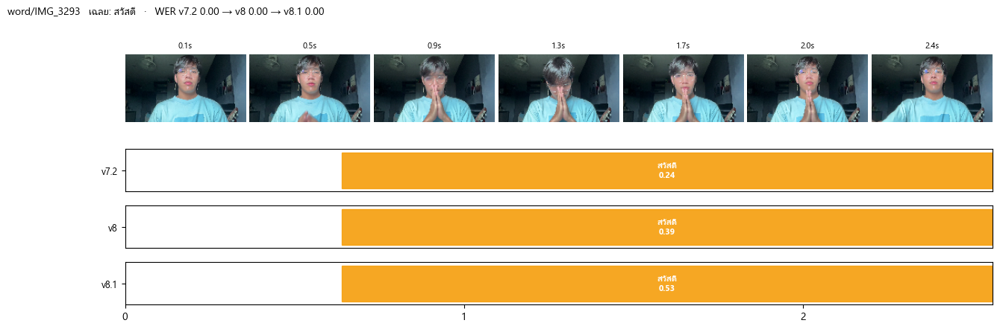

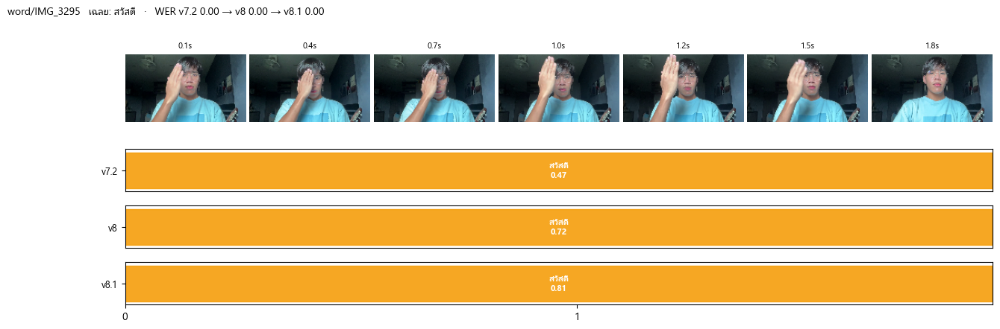

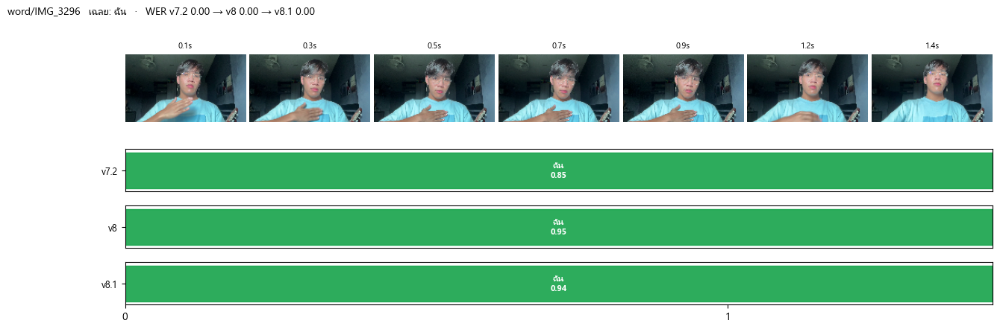

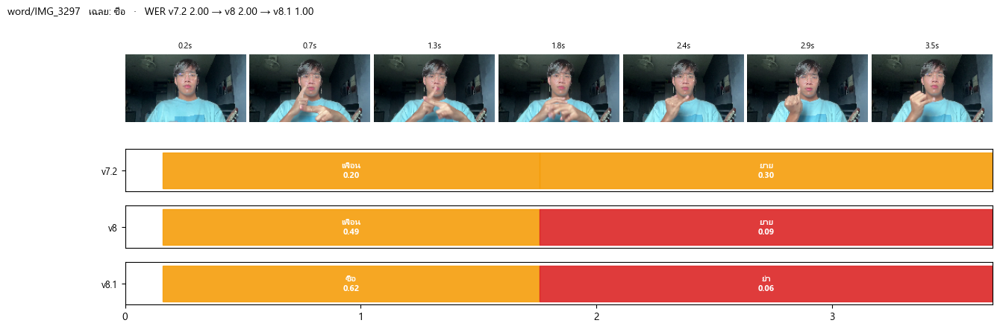

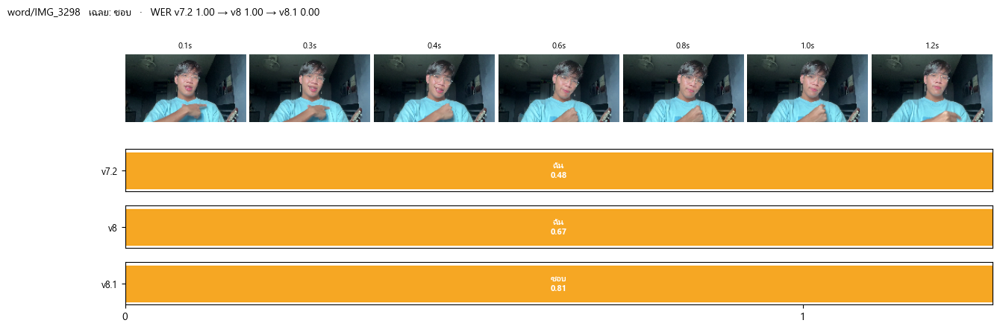

...

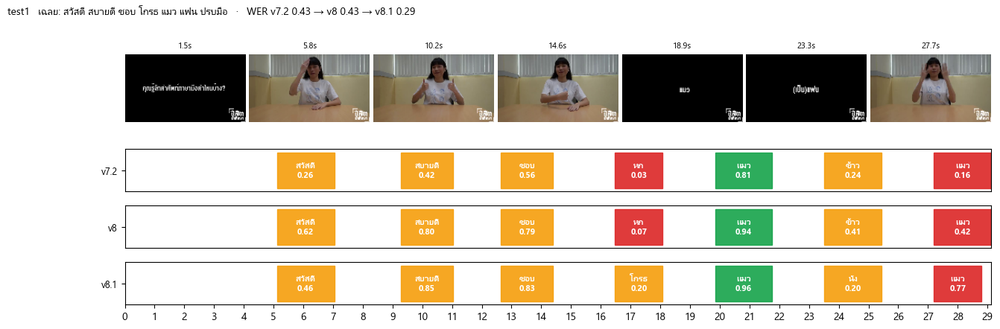

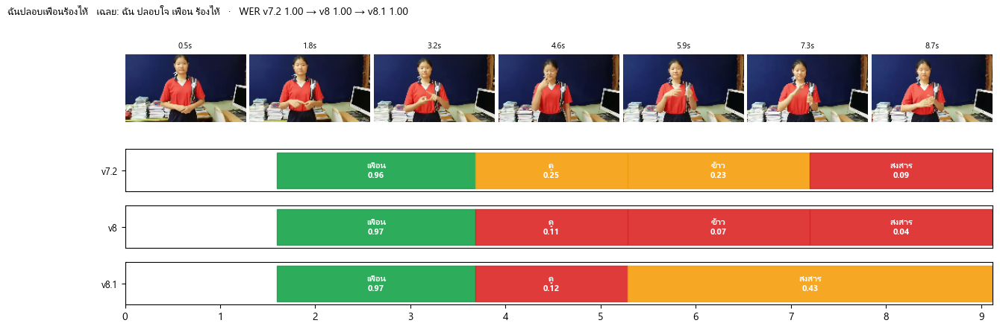

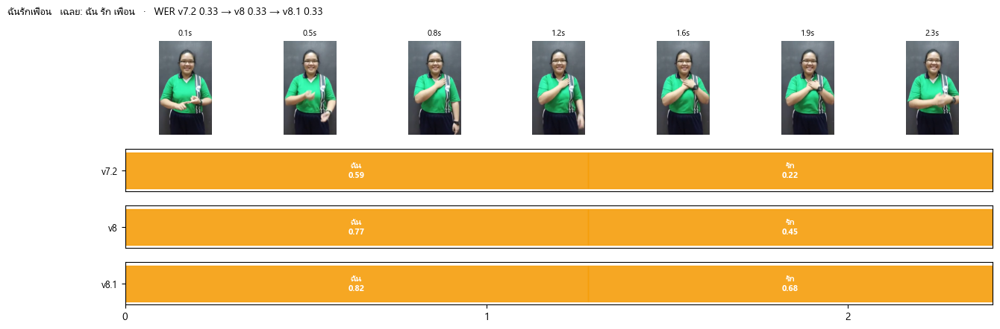

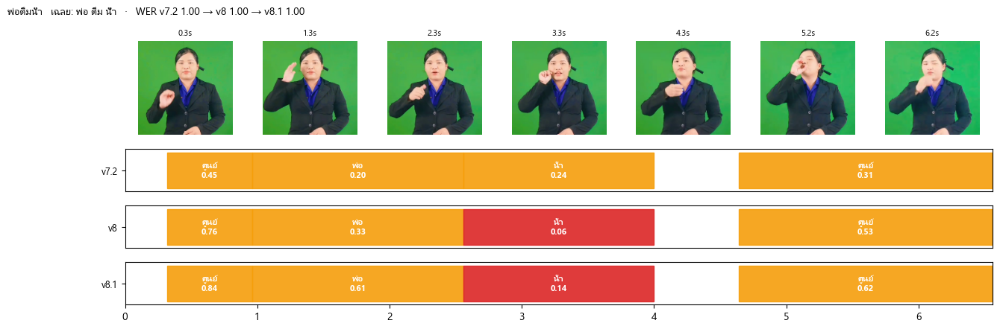

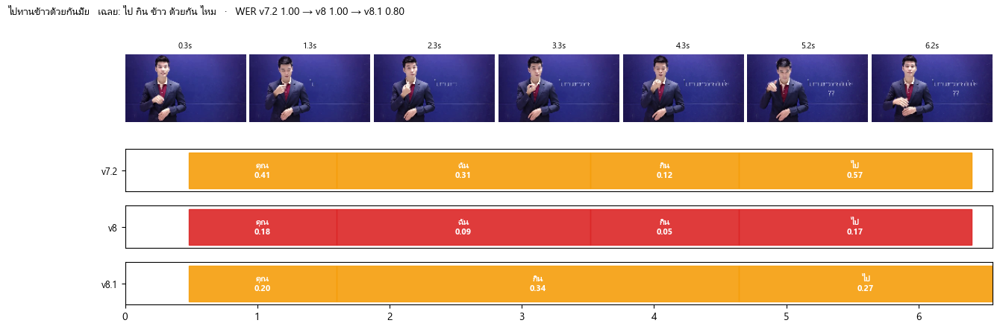

In [4]:
# 2-4) ภาพต่อคลิป: แถวบน = เฟรมจากวิดีโอ · แถวล่าง = กล่องคำตามเวลาของแต่ละเวอร์ชัน (เขียว Accept / ส้ม Uncertain / แดง Reject) + P(correct)
import cv2, matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["Leelawadee UI", "Tahoma", "DejaVu Sans"]
COL = {"accepted": "#16a34a", "uncertain": "#f59e0b", "unknown": "#dc2626"}

def frames(video, ts, w=150):
    cap, out = cv2.VideoCapture(str(video)), []
    for t in ts:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000); ok, f = cap.read()
        out.append(cv2.cvtColor(cv2.resize(f, (w, int(w * f.shape[0] / f.shape[1]))), cv2.COLOR_BGR2RGB) if ok else None)
    cap.release(); return out

def card(name, i):
    us = {v: REP["utterances"][name][v][i] for v in VER}
    u = us["v8.1"]; uid = u["id"]
    video = ROOT / "data_test" / f"{uid}.mp4" if name == "data_test" else ROOT / "cache/iphone_test_mp4" / f"{uid.replace('/', '_')}.mp4"
    dur = max([s["t1"] for v in VER for s in us[v]["segments"]] + [1.0])
    ts = np.linspace(0.05, 0.95, 7) * dur
    fig = plt.figure(figsize=(15, 4.6)); gs = fig.add_gridspec(4, 7, height_ratios=[2.2, 1, 1, 1], hspace=0.25, wspace=0.03)
    for k, (t, im) in enumerate(zip(ts, frames(video, ts))):
        a = fig.add_subplot(gs[0, k]); a.axis("off")
        if im is not None: a.imshow(im)
        a.set_title(f"{t:.1f}s", fontsize=8)
    for r, v in enumerate(VER, 1):
        a = fig.add_subplot(gs[r, :]); a.set_xlim(0, dur); a.set_ylim(0, 1); a.set_yticks([0.5]); a.set_yticklabels([v], fontsize=9)
        a.set_xticks([] if r < 3 else np.arange(0, dur + 0.01, 1.0))
        for s in us[v]["segments"]:
            a.add_patch(plt.Rectangle((s["t0"], 0.08), max(s["t1"] - s["t0"], 0.05), 0.84, color=COL[s["status"]], alpha=0.9))
            a.text((s["t0"] + s["t1"]) / 2, 0.5, f"{s['word']}\n{s['p']:.2f}", ha="center", va="center", fontsize=8, color="white", fontweight="bold", clip_on=True)
    fig.suptitle(f"{uid}   เฉลย: {' '.join(u['ref'])}   ·   WER v7.2 {us['v7.2']['wer']:.2f} → v8 {us['v8']['wer']:.2f} → v8.1 {us['v8.1']['wer']:.2f}", fontsize=10, x=0.02, ha="left")
    plt.show()

for name in ("iphone_word", "iphone_sentence", "data_test"):
    for i in range(len(REP["utterances"][name]["v8.1"])):
        card(name, i)

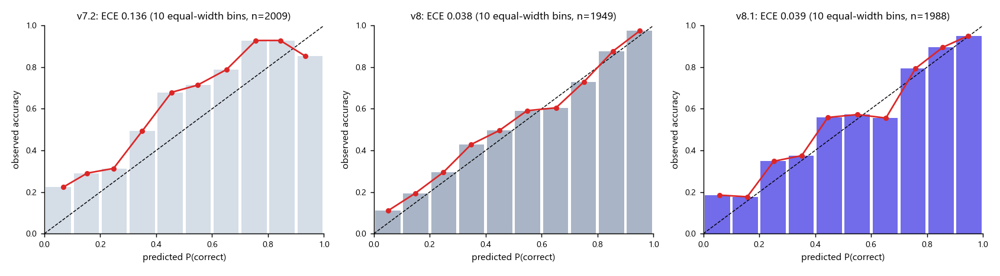

,diff,lo,hi,better,worse,n
TSL51 1×,-0.085,-0.118,-0.051,42.000000,10.000000,126.000000
TSL51 1.5×,-0.079,-0.112,-0.048,40.000000,8.000000,126.000000
TSL51 2×,-0.084,-0.116,-0.054,38.000000,6.000000,126.000000
คำเดี่ยว (คนใหม่),-0.041,-0.083,+0.000,14.000000,5.000000,217.000000
ประโยคลื่น,-0.051,-0.085,-0.018,36.000000,15.000000,120.000000
data_test,-0.069,-0.149,+0.000,2.000000,0.000000,5.000000
iPhone คำ,-0.222,-0.556,+0.000,2.000000,0.000000,9.000000
iPhone ประโยค,-0.157,-0.357,+0.000,2.000000,0.000000,5.000000


In [5]:
# 2-5) ความน่าเชื่อถือของ P(correct) (test sets รวม) + ผลต่าง WER แบบ paired bootstrap (95% CI) v8.1 − v8
from IPython.display import Image, display
display(Image(str(ROOT / "result_reporting/figures_v8.1/reliability.png")))
bs = pd.DataFrame({SETS[s]: {k: REP["bootstrap"][s]["v8.1-v8"][k] for k in ("diff", "lo", "hi", "better", "worse", "n")} for s in SETS}).T
bs.style.format({"diff": "{:+.3f}", "lo": "{:+.3f}", "hi": "{:+.3f}"})